<b><font size="6" color="#E8800A">Feature selection, final model and predictions</font></b><br>

This notebook continues from nb2 and nb3. It reads the cleaned training file and the cleaning log written by nb2, passes `test.csv` through the same repairs, selects the features, assesses the final model and writes the predictions for Kaggle.

In [1]:
import sys
import warnings
from collections import Counter
from pathlib import Path

# course_helpers.py sits beside the notebook.
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, fbeta_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit, TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

from course_helpers import CleaningLog, PLOT_BLUE, PLOT_ORANGE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)  # For reproducibility

In [2]:
train = pd.read_csv("../data/interim/train_cleaned.csv",
                    index_col="ID", parse_dates=["purchase_date"])
train_raw = pd.read_csv("../data/train.csv", index_col="ID")
clients_df = pd.read_csv("../data/clientes.csv", index_col="customer_id")

recipe_log = CleaningLog.load("../logs/train_cleaning_log.json")
fill_step = recipe_log.plan("feature columns")
logged_numeric, logged_categorical = fill_step["numeric"], fill_step["categorical"]
log1p_columns = recipe_log.plan("log1p columns")["columns"]
target = "repeat_purchase_90d"

print(f"train {train.shape[0]:,} rows")
print(f"{len(logged_numeric)} numeric and {len(logged_categorical)} categorical columns in the log,"
      f" log1p on {len(log1p_columns)}")

train 6,469 rows
29 numeric and 6 categorical columns in the log, log1p on 26


<b><font size="6" color="#E8800A">Cleaning the test set</font></b><br>

In nb2 the repairs that only use values from the same row were applied directly to the training data. The function below repeats them, in the same order, so that `test.csv` goes through exactly the same steps. None of them learns anything from the data, so applying them to the test rows uses no information from the training set and vice versa.

In [3]:
def repair(frame):
    """The same-row repairs of nb2, as one function that also runs on test.csv."""
    out = frame.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"], format="%Y-%m-%d")
    count = out["prior_purchase_count"]

    # prior_mean_purchase_value = prior_total_spend / prior_purchase_count
    has_history = count > 0
    out.loc[has_history, "prior_mean_purchase_value"] = (
        out.loc[has_history, "prior_total_spend"] / count[has_history])

    # -4 is a placeholder; the mean gap is recomputed where the formula applies
    out["prior_mean_gap_days"] = out["prior_mean_gap_days"].replace(-4, np.nan)
    days = out["days_since_previous_purchase"]
    gap_rows = (count > 1) & (days >= 0)
    out.loc[gap_rows, "prior_mean_gap_days"] = (
        (out.loc[gap_rows, "customer_tenure_days"] - days[gap_rows])
        / (count[gap_rows] - 1))

    # spend_365d: inconsistent values blanked, then filled where the window
    # holds all of the history or none of it
    s = out["spend_365d"]
    inconsistent = s.notna() & ((s < out["spend_180d"])
                                | (s > out["prior_total_spend"] + 0.01))
    out.loc[inconsistent, "spend_365d"] = np.nan
    c365 = out["purchase_count_365d"]
    m = out["spend_365d"].isna() & c365.eq(count)
    out.loc[m, "spend_365d"] = out.loc[m, "prior_total_spend"]
    m = out["spend_365d"].isna() & c365.eq(0)
    out.loc[m, "spend_365d"] = 0.0

    # one gap or one purchase: no spread, 0 by convention
    m = count.eq(2) & out["prior_std_gap_days"].isna()
    out.loc[m, "prior_std_gap_days"] = 0.0
    m = count.eq(1) & out["prior_std_purchase_value"].isna()
    out.loc[m, "prior_std_purchase_value"] = 0.0

    # negative day counts and window spends are impossible
    for column in ["days_since_previous_purchase", "spend_365d"]:
        out.loc[out[column] < 0, column] = np.nan
    return out

To check the function, we run it on the original `train.csv` (without the 65 empty rows) and compare the result with the file nb2 wrote.

In [4]:
features_raw = [c for c in train_raw.columns if c not in ("customer_id", target)]
check = repair(train_raw.dropna(subset=features_raw, how="all"))

different = []
for column in train.columns:
    a, b = check[column], train[column]
    if pd.api.types.is_numeric_dtype(a):
        same = np.isclose(a, b, rtol=1e-9, atol=1e-9, equal_nan=True)
    else:
        same = (a == b) | (a.isna() & b.isna())
    if not same.all():
        different.append(column)
print("same rows as train_cleaned.csv:", check.index.equals(train.index))
print("columns that differ:", different if different else "none")

same rows as train_cleaned.csv: True
columns that differ: none


The function reproduces `train_cleaned.csv` exactly, so it can be applied to `test.csv` at the end of the notebook. Until then the test set is not used.

<b><font size="6" color="#E8800A">Columns left out of the model</font></b><br>

Before selecting features, we removed the columns that should not reach the model at all. The cells below show the evidence for each decision.

In [5]:
# random_noise: no relation with the target
print(f"AUC of random_noise against the target: {roc_auc_score(train[target], train['random_noise']):.3f}")

# document_series: each series belongs to a period of time
print("\nrows per year and document series (train):")
print(pd.crosstab(train["purchase_date"].dt.year, train["document_series"]).to_string())

AUC of random_noise against the target: 0.495

rows per year and document series (train):
document_series  Ctrl Z Series 1  Ctrl Z Series 2  Ctrl Z Series 3
purchase_date                                                     
2015                           0                0              335
2016                           0                0              420
2017                         281                0              389
2018                         387                0              329
2019                         397                0              249
2020                         532                0              138
2021                         231              508               43
2022                           0              628                0
2023                           0              767                0
2024                           0              757                0
2025                           0               78                0


In [6]:
# transport_method: how many customers use each level
customers_per_level = train.groupby("transport_method")["customer_id"].nunique()
print(f"transport_method: {len(customers_per_level)} levels,"
      f" {(customers_per_level == 1).sum()} used by a single customer,"
      f" {(customers_per_level < 5).sum()} by fewer than 5")

# clientes.csv: missing values and how close each column is to an identifier
clients_summary = pd.DataFrame({
    "% missing": 100 * clients_df.isna().mean(),
    "distinct values": clients_df.nunique(),
}).round(1)
print(f"\nclientes.csv: {len(clients_df):,} customers")
print(clients_summary.to_string())

transport_method: 80 levels, 40 used by a single customer, 48 by fewer than 5

clientes.csv: 1,143 customers
                     % missing  distinct values
country_or_region          0.0               11
commercial_region         10.0               37
island                    50.6               10
municipality              13.9              183
city                      47.8              417
postal_area                6.2              271
postal_code               14.9              828
street                    52.3              511
address                    0.5             1120
customer_type            100.0                0
company_name               0.0             1141
customer_since_year        0.0               12


- **`random_noise`**: its AUC against the target is about 0.5, the value of a random guess, and in nb2 removing it made no difference to the F1 score. It is left out.
- **`document_series`**: series 3 only appears up to 2021, series 1 between 2017 and 2021 and series 2 from 2021 onwards. The column tells the model *when* a purchase happened, not anything about the customer. In nb1 we saw that the test purchases are later than every training purchase, so the series would carry no useful information there. It is left out.
- **`transport_method`**: many levels are used by a single customer, so a level can work as a customer identifier. Levels used by fewer than 5 customers in the training rows are grouped into one level, `rare`.
- **`clientes.csv`**: `customer_type` is always empty, `company_name` and `address` are different for almost every customer (they work as identifiers), and the remaining columns are mostly missing or have hundreds of levels. We did not join it to the training data.
- **`customer_id`** and **`purchase_date`** stay out, as in nb2 and nb3: the first is an identifier and the second is only used to order the rows in time.

In [7]:
numeric = [c for c in logged_numeric if c != "random_noise"]
categorical = [c for c in logged_categorical if c != "document_series"]
rare_columns = ["transport_method"]
MIN_CUSTOMERS = 5
print(f"{len(numeric)} numeric and {len(categorical)} categorical columns go to the model")

28 numeric and 5 categorical columns go to the model


<b><font size="6" color="#E8800A">Preparing each split</font></b><br>

The recipe chosen in nb2 is applied inside every split, fitted on the training rows only: rare levels grouped, `log1p` on the logged columns, KNN imputation (k=5) on standardised numeric columns and the mode for categorical ones, one-hot encoding and min-max scaling. We use the same 20 splits grouped by `customer_id` as nb2 and nb3.

nb3 compared four encoders and four scalers. The sixteen combinations scored between 0.7042 and 0.7101, with standard errors of about 0.014, so none of them is really better than the others. We use one-hot encoding because target encoding replaces each level with its repeat rate in the training rows, and for `transport_method`, where many levels belong to a single customer, that amounts to memorising customers. Min-max scaling is the scaler that scored highest in nb2.

In [8]:
def group_rare(train, test, columns, min_customers=MIN_CUSTOMERS):
    """Levels used by fewer than `min_customers` training customers become 'rare'."""
    train, test = train.copy(), test.copy()
    for column in columns:
        per_level = train.groupby(column)["customer_id"].nunique()
        common = set(per_level[per_level >= min_customers].index)
        for half in (train, test):
            known = half[column].notna()
            half.loc[known & ~half[column].isin(common), column] = "rare"
    return train, test


def fill_missing(train, test, plan):
    """Fill every missing value with imputers fitted on `train` alone."""
    train, test = train.copy(), test.copy()
    for columns, imputer in plan:
        blocks = [half[columns].astype(object).fillna(np.nan).infer_objects()
                  for half in (train, test)]
        if isinstance(imputer, KNNImputer):
            # KNN measures distances, so it works on standardised columns and
            # its fills go back in the columns' own units.
            scale = StandardScaler().fit(blocks[0])
            imputer.fit(scale.transform(blocks[0]))
            filled = [scale.inverse_transform(imputer.transform(scale.transform(block)))
                      for block in blocks]
        else:
            imputer.fit(blocks[0])
            filled = [imputer.transform(block) for block in blocks]
        train[columns], test[columns] = filled
    return train, test


def fold_matrices(train, test, numeric, categorical, rare=rare_columns):
    """Return (A_train, A_test, names) for one split, every step fitted on `train`."""
    train, test = group_rare(train, test, rare)
    train, test = train.copy(), test.copy()
    for half in (train, test):
        half[log1p_columns] = np.log1p(half[log1p_columns].clip(lower=0))
    train, test = fill_missing(train, test,
                               [(numeric, KNNImputer(n_neighbors=5)),
                                (categorical, SimpleImputer(strategy="most_frequent"))])
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    cat_train = encoder.fit_transform(train[categorical])
    cat_test = encoder.transform(test[categorical])
    scaler = MinMaxScaler().fit(train[numeric])
    num_train, num_test = scaler.transform(train[numeric]), scaler.transform(test[numeric])
    names = list(encoder.get_feature_names_out(categorical)) + list(numeric)
    return (np.hstack([cat_train, num_train]), np.hstack([cat_test, num_test]),
            np.asarray(names))

In [9]:
y = train[target]
splitter = GroupShuffleSplit(n_splits=20, test_size=0.2, random_state=RANDOM_STATE)
splits = list(splitter.split(train, y, groups=train["customer_id"]))


def build(numeric, categorical, rare=rare_columns):
    """The prepared matrices of every split, built once and reused below."""
    return [(*fold_matrices(train.iloc[tr], train.iloc[te], numeric, categorical, rare),
             y.iloc[tr].to_numpy(), y.iloc[te].to_numpy())
            for tr, te in splits]


matrices = build(numeric, categorical)
logged_matrices = build(logged_numeric, logged_categorical, rare=[])
print(f"{len(splits)} splits, {matrices[0][0].shape[1]} columns after encoding"
      f" ({logged_matrices[0][0].shape[1]} with every logged column and no grouping)")

20 splits, 82 columns after encoding (127 with every logged column and no grouping)


In [10]:
def model():
    return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)


def heldout_f1(matrices, select=None):
    """Held-out F1 and AUC on every split; `select()` builds a fresh selector per split."""
    rows = []
    for A_train, A_test, names, y_train, y_test in matrices:
        selector, keep = None, np.ones(A_train.shape[1], dtype=bool)
        if select is not None:
            selector = select().fit(A_train, y_train)
            keep = selector.get_support()
        fitted = model().fit(A_train[:, keep], y_train)
        rows.append({"n": int(keep.sum()),
                     "F1": f1_score(y_test, fitted.predict(A_test[:, keep])),
                     "AUC": roc_auc_score(y_test, fitted.predict_proba(A_test[:, keep])[:, 1]),
                     "iterations": int(fitted.n_iter_.max()),
                     "kept": list(names[keep]), "selector": selector})
    return pd.DataFrame(rows)


def paired_delta(scores, reference):
    """Mean split-by-split difference from `reference`, its SEM, wins and verdict."""
    delta = np.asarray(scores) - np.asarray(reference)
    sem = delta.std(ddof=1) / np.sqrt(len(delta))
    verdict = ("identical on every split" if not delta.any()
               else "inside the noise" if abs(delta.mean()) <= 2 * sem
               else "better" if delta.mean() > 0 else "worse")
    return {"dF1": delta.mean(), "SEM": sem,
            "wins": f"{int((delta > 0).sum())}/{len(delta)}", "verdict": verdict}


always_repeat = np.mean([f1_score(y_test, np.ones(len(y_test)))
                         for *_, y_test in matrices])
reference = heldout_f1(matrices)
logged = heldout_f1(logged_matrices)

print(f"always-repeat F1        {always_repeat:.4f}")
print(f"every logged column     F1 {logged['F1'].mean():.4f}  AUC {logged['AUC'].mean():.4f}"
      f"  ({logged['n'].mean():.0f} columns)")
print(f"after the decisions     F1 {reference['F1'].mean():.4f}  AUC {reference['AUC'].mean():.4f}"
      f"  ({reference['n'].mean():.0f} columns)")
print("decisions vs every logged column:", paired_delta(reference["F1"], logged["F1"]))
print("most iterations the solver needed:", reference["iterations"].max())

always-repeat F1        0.6945
every logged column     F1 0.7109  AUC 0.7604  (128 columns)
after the decisions     F1 0.7109  AUC 0.7593  (83 columns)
decisions vs every logged column: {'dF1': np.float64(-4.826909471915553e-05), 'SEM': np.float64(0.0014423784703884361), 'wins': '13/20', 'verdict': 'inside the noise'}
most iterations the solver needed: 102


With these columns removed and the rare levels grouped, the model has 83 columns instead of 128 and the F1 score does not change: 0.7109 in both cases, a paired difference of -0.0000 ± 0.0014. Both are only slightly above predicting a repeat purchase for every row (0.6945). The solver converges in every split (at most 102 of the 1,000 iterations), so these scores do not depend on the computer the notebook runs on.

<b><font size="6" color="#E8800A">Feature selection</font></b><br>

We used one method from each of the three families seen in class: a **filter** (correlation with the target, skipping redundant columns), a **wrapper** (`RFE` with a logistic regression) and an **embedded** method (logistic regression with an L1 penalty). Every selector is fitted inside each training split, so the held-out rows never take part in choosing the features. Each result is compared with the model that uses all the columns, split by split.

The code for the filter and for the vote is adapted from the week 4 practical.

In [11]:
def cramers_v(column, outcome):
    """Chi-square on a contingency table, rescaled to [0, 1]."""
    table = pd.crosstab(column, outcome)
    if min(table.shape) < 2:
        return 0.0, float("nan"), 0.0, float(table.to_numpy().min())
    statistic, p, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return statistic, p, v, expected.min()


def encoded_effect_scores(matrix, outcome):
    """Cramer's V for the one-hot columns, |point-biserial r| for the numeric ones."""
    matrix = np.asarray(matrix, dtype=float)
    categorical_width = matrix.shape[1] - len(numeric)
    target_values = np.asarray(outcome, dtype=int)
    scores = []
    for position in range(matrix.shape[1]):
        values = matrix[:, position]
        if position < categorical_width:
            effect = cramers_v(pd.Series(values), pd.Series(target_values))[2]
        else:
            effect = abs(pointbiserialr(target_values, values).statistic)
        scores.append(effect)
    return np.nan_to_num(np.asarray(scores, dtype=float))


class CorrelationFilter:
    """Rank by relevance to the target, then skip columns redundant with one already kept."""

    def __init__(self, k, redundancy=None):
        self.k = k
        self.redundancy = redundancy

    def fit(self, matrix, outcome):
        matrix = np.asarray(matrix, dtype=float)
        with np.errstate(invalid="ignore", divide="ignore"):
            relevance = encoded_effect_scores(matrix, outcome)
            between = np.nan_to_num(np.abs(np.corrcoef(matrix, rowvar=False)))
        keep = []
        for candidate in np.argsort(relevance)[::-1]:
            if len(keep) == self.k:
                break
            if self.redundancy is not None and any(
                between[candidate, chosen] > self.redundancy for chosen in keep
            ):
                continue
            keep.append(int(candidate))
        self.support_ = np.zeros(matrix.shape[1], dtype=bool)
        self.support_[keep] = True
        return self

    def get_support(self):
        return self.support_


REDUNDANT = 0.70   # above this, a pair of columns is treated as the same information

<b><font size="5" color="#E8800A">Filter</font></b><br>

In [12]:
widths = [10, 20, 30, 40, 50]
filter_runs = {k: heldout_f1(matrices, select=lambda: CorrelationFilter(k, redundancy=REDUNDANT))
               for k in widths}
filter_curve = pd.DataFrame([{"k": k, "F1": run["F1"].mean(), "AUC": run["AUC"].mean(),
                              **paired_delta(run["F1"], reference["F1"])}
                             for k, run in filter_runs.items()])
filter_k = int(filter_curve.loc[filter_curve["F1"] == filter_curve["F1"].max(), "k"].min())
print(filter_curve.round(4).to_string(index=False))
print(f"filter width with the highest mean F1: k = {filter_k}")

 k     F1    AUC     dF1    SEM wins          verdict
10 0.7068 0.7463 -0.0040 0.0031 7/20 inside the noise
20 0.7067 0.7495 -0.0042 0.0016 6/20            worse
30 0.7088 0.7511 -0.0021 0.0012 6/20 inside the noise
40 0.7103 0.7542 -0.0006 0.0012 8/20 inside the noise
50 0.7118 0.7549  0.0009 0.0015 9/20 inside the noise
filter width with the highest mean F1: k = 50


<b><font size="5" color="#E8800A">Wrapper: RFE</font></b><br>

In [13]:
widths = [10, 20, 30, 40, 50, 60]
rfe_runs = {k: heldout_f1(matrices, select=lambda: RFE(model(), n_features_to_select=k))
            for k in widths}
rfe_curve = pd.DataFrame([{"k": k, "F1": run["F1"].mean(), "AUC": run["AUC"].mean(),
                           **paired_delta(run["F1"], reference["F1"])}
                          for k, run in rfe_runs.items()])
rfe_k = int(rfe_curve.loc[rfe_curve["F1"] == rfe_curve["F1"].max(), "k"].min())
print(rfe_curve.round(4).to_string(index=False))
print(f"RFE width with the highest mean F1: k = {rfe_k}")

 k     F1    AUC     dF1    SEM  wins          verdict
10 0.7019 0.7482 -0.0089 0.0027  4/20            worse
20 0.7080 0.7555 -0.0028 0.0015  7/20 inside the noise
30 0.7121 0.7583  0.0013 0.0016 10/20 inside the noise
40 0.7128 0.7595  0.0019 0.0013  9/20 inside the noise
50 0.7119 0.7595  0.0011 0.0013 12/20 inside the noise
60 0.7104 0.7591 -0.0005 0.0006  9/20 inside the noise
RFE width with the highest mean F1: k = 40


<b><font size="5" color="#E8800A">Embedded: L1 penalty</font></b><br>

In [14]:
def l1_selector(C):
    return SelectFromModel(LogisticRegression(l1_ratio=1, solver="liblinear", C=C,
                                              max_iter=1000, random_state=RANDOM_STATE),
                           threshold=1e-8)


l1_runs = {C: heldout_f1(matrices, select=lambda: l1_selector(C)) for C in [0.05, 0.1, 0.5, 1.0]}
l1_board = pd.DataFrame([{"C": C, "columns": run["n"].mean(), "F1": run["F1"].mean(),
                          "AUC": run["AUC"].mean(), **paired_delta(run["F1"], reference["F1"])}
                         for C, run in l1_runs.items()])
print(l1_board.round(4).to_string(index=False))

   C  columns     F1    AUC     dF1    SEM  wins          verdict
0.05    10.00 0.7043 0.7533 -0.0066 0.0020  5/20            worse
0.10    18.75 0.7109 0.7567  0.0000 0.0014 11/20 inside the noise
0.50    47.05 0.7122 0.7592  0.0013 0.0008 14/20 inside the noise
1.00    57.95 0.7108 0.7588 -0.0001 0.0010 10/20 inside the noise


No single method beats the model with all the columns by more than the noise:
- the **filter** is best with 50 columns (F1 0.7118, +0.0009 ± 0.0015) and loses with fewer;
- **RFE** peaks at 40 columns (F1 0.7128, +0.0019 ± 0.0013);
- the **L1** model with `C=0.1` keeps about 19 columns and scores the same as all the columns (F1 0.7109); a stronger penalty (`C=0.05`, 10 columns) is worse.

The widths were chosen on the same 20 splits that score them, so the best point of each curve is slightly optimistic.

<b><font size="5" color="#E8800A">Combining the three families: a vote</font></b><br>

Each family looks at the columns in a different way, so instead of trusting only one of them we kept a column when at least two of the three methods selected it (`Vote` from the week 4 practical). The filter and `RFE` use the widths chosen above and the L1 model uses `C=0.1`, the strongest penalty that did not lose against all the columns.

In [15]:
class Vote:
    """Keep the columns that at least `minimum` of the members select."""

    def __init__(self, members, minimum):
        self.members = members
        self.minimum = minimum

    def fit(self, matrix, outcome):
        self.decisions_ = pd.DataFrame(
            {name: member.fit(matrix, outcome).get_support()
             for name, member in self.members.items()})
        self.support_ = (self.decisions_.sum(axis=1) >= self.minimum).to_numpy()
        self.decisions_["kept"] = self.support_
        return self

    def get_support(self):
        return self.support_


def three_families():
    return {"filter": CorrelationFilter(filter_k, redundancy=REDUNDANT),
            "wrapper": RFE(model(), n_features_to_select=rfe_k),
            "embedded": l1_selector(0.1)}


vote = heldout_f1(matrices, select=lambda: Vote(three_families(), minimum=2))
print(f"vote: F1 {vote['F1'].mean():.4f}  AUC {vote['AUC'].mean():.4f}"
      f"  ({vote['n'].mean():.1f} columns)")
print("vs all columns:", paired_delta(vote["F1"], reference["F1"]))
print(f"AUC difference: {(vote['AUC'] - reference['AUC']).mean():+.4f}"
      f" +/- {(vote['AUC'] - reference['AUC']).sem():.4f}")

vote: F1 0.7143  AUC 0.7589  (33.5 columns)
vs all columns: {'dF1': np.float64(0.0034837830529364346), 'SEM': np.float64(0.0010674940556368684), 'wins': '16/20', 'verdict': 'better'}
AUC difference: -0.0004 +/- 0.0007


In [16]:
# How often each family, and the vote, kept each column over the 20 splits.
counts = pd.concat([run.decisions_.set_axis(names)
                    for run, (_, _, names, _, _) in zip(vote["selector"], matrices)]
                   ).groupby(level=0).sum()
kept_most = counts[counts["kept"] > len(splits) / 2].sort_values(
    ["kept", "embedded", "wrapper", "filter"], ascending=False)
final_features = list(kept_most.index)
print(f"{len(final_features)} columns kept by the vote in most of the {len(splits)} splits")
print((kept_most.astype(int).astype(str) + f"/{len(splits)}").to_string())

31 columns kept by the vote in most of the 20 splits
                                            filter wrapper embedded   kept
Total Desc_ Linha                            20/20   20/20    20/20  20/20
purchase_count_365d                          20/20   20/20    20/20  20/20
Custo                                        18/20   20/20    20/20  20/20
prior_mean_gap_days                           4/20   20/20    20/20  20/20
purchase_count_90d                            1/20   20/20    20/20  20/20
Total Imp_                                   19/20   19/20    20/20  20/20
transport_method_Maybe Tomorrow Delivery 68  20/20   20/20    19/20  20/20
transport_method_Maybe Tomorrow Delivery 51  20/20   20/20    16/20  20/20
transport_method_Maybe Tomorrow Delivery 53  20/20   19/20    15/20  20/20
salesperson_VLOOKUP Master 6                 20/20   20/20     0/20  20/20
salesperson_VLOOKUP Master 8                 20/20   20/20     0/20  20/20
salesperson_VLOOKUP Master 4                 17

The vote keeps 33.5 columns on average and is the only option that is better than all the columns: F1 0.7143 against 0.7109, a paired difference of +0.0035 ± 0.0011, ahead in 16 of the 20 splits. The ROC-AUC does not change (-0.0004 ± 0.0007).

The 31 columns kept in most of the splits are the final feature set. They include the purchase counts of the previous 30, 90 and 365 days, the gaps between previous purchases (`prior_mean_gap_days`, `prior_std_gap_days`), values of the current purchase (`Custo`, `Total Imp_`, `Total Desc_ Linha`) and some levels of `transport_method`, `salesperson` and `payment_type`. The families often disagree: `prior_mean_gap_days` is kept by RFE and L1 in every split but by the filter in only 4, which is why we preferred a vote to a single method.

<b><font size="6" color="#E8800A">Assessing the final model</font></b><br>

The final model is a logistic regression on the columns kept by the vote. Besides the splits grouped by customer, we assessed it with `TimeSeriesSplit` (week 5 practical): the rows are sorted by `purchase_date` and every fold trains on the past and validates on the period that follows. This is closer to the Kaggle test set, which contains later purchases of mostly the same customers.

We report F1, because it is the metric we used in every comparison, and ROC-AUC, which does not depend on the 0.5 threshold. Both are compared with predicting a repeat purchase for every row.

In [17]:
order = train["purchase_date"].sort_values(kind="stable").index
X_time = train.loc[order]
y_time = X_time[target]
tscv = TimeSeriesSplit(n_splits=5)

time_rows, y_val, y_pred_proba_val = [], [], []
for fold, (tr, va) in enumerate(tscv.split(X_time), start=1):
    A_train, A_val, names = fold_matrices(X_time.iloc[tr], X_time.iloc[va], numeric, categorical)
    keep = np.isin(names, final_features)
    every = model().fit(A_train, y_time.iloc[tr])
    final = model().fit(A_train[:, keep], y_time.iloc[tr])
    proba = final.predict_proba(A_val[:, keep])[:, 1]
    period = X_time["purchase_date"].iloc[va]
    time_rows.append({
        "fold": fold,
        "validates": f"{period.min():%Y-%m} to {period.max():%Y-%m}",
        "F1 final model": f1_score(y_time.iloc[va], proba >= 0.5),
        "F1 all columns": f1_score(y_time.iloc[va], every.predict(A_val)),
        "F1 always repeat": f1_score(y_time.iloc[va], np.ones(len(va))),
        "AUC final model": roc_auc_score(y_time.iloc[va], proba),
    })
    y_val.append(y_time.iloc[va].to_numpy())
    y_pred_proba_val.append(proba)

time_board = pd.DataFrame(time_rows)
y_val, y_pred_proba_val = np.concatenate(y_val), np.concatenate(y_pred_proba_val)
print(time_board.round(4).to_string(index=False))
print("\nmean:", time_board.drop(columns=["fold", "validates"]).mean().round(4).to_dict())

 fold          validates  F1 final model  F1 all columns  F1 always repeat  AUC final model
    1 2017-08 to 2019-01          0.7786          0.7649            0.7377           0.7984
    2 2019-01 to 2020-10          0.7354          0.7402            0.6965           0.7814
    3 2020-10 to 2022-03          0.7542          0.7441            0.7310           0.7979
    4 2022-03 to 2023-09          0.7296          0.7227            0.6846           0.7947
    5 2023-09 to 2025-02          0.7811          0.7591            0.7530           0.7966

mean: {'F1 final model': 0.7558, 'F1 all columns': 0.7462, 'F1 always repeat': 0.7206, 'AUC final model': 0.7938}


In [18]:
def metrics_at(threshold):
    """Score the validation labels the model gives at one threshold."""
    labels = (y_pred_proba_val >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, labels).ravel()
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, labels),
        "precision": precision_score(y_val, labels, zero_division=0),
        "recall": recall_score(y_val, labels),
        "FPR": fp / (fp + tn),
        "F0.5": fbeta_score(y_val, labels, beta=0.5, zero_division=0),
        "F1": f1_score(y_val, labels, zero_division=0),
        "F2": fbeta_score(y_val, labels, beta=2, zero_division=0),
    }


print(pd.DataFrame([metrics_at(t) for t in [0.3, 0.4, 0.5, 0.6, 0.7]]).round(4).to_string(index=False))
print("\nconfusion matrix at 0.5 (rows: actual 0/1, columns: predicted 0/1)")
print(confusion_matrix(y_val, (y_pred_proba_val >= 0.5).astype(int)))

 threshold  accuracy  precision  recall    FPR   F0.5     F1     F2
       0.3    0.6434     0.6223  0.9352 0.7337 0.6669 0.7473 0.8497
       0.4    0.6976     0.6852  0.8575 0.5091 0.7139 0.7618 0.8165
       0.5    0.7234     0.7500  0.7641 0.3292 0.7528 0.7570 0.7612
       0.6    0.7187     0.8138  0.6499 0.1923 0.7747 0.7226 0.6772
       0.7    0.6798     0.8547  0.5206 0.1144 0.7574 0.6470 0.5647

confusion matrix at 0.5 (rows: actual 0/1, columns: predicted 0/1)
[[1577  774]
 [ 717 2322]]


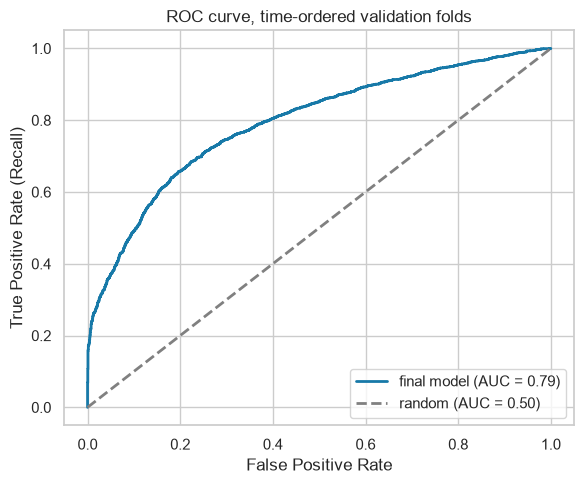

In [19]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba_val)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color=PLOT_BLUE, lw=2,
         label=f"final model (AUC = {roc_auc_score(y_val, y_pred_proba_val):.2f})")
plt.plot([0, 1], [0, 1], color="gray", lw=2, linestyle="--", label="random (AUC = 0.50)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curve, time-ordered validation folds")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In the time-ordered folds the final model has a mean F1 of 0.7558, against 0.7462 with all the columns and 0.7206 when predicting a repeat purchase for every row, and it is the best of the three in four of the five periods. Its ROC-AUC is 0.79, higher than in the grouped splits (0.76), because here, as in the test set, most validation customers were already seen in training.

At the 0.5 threshold precision and recall are balanced (0.75 and 0.76). A threshold of 0.4 gives a slightly higher F1 (0.7618), but the gain is small and it would be chosen on these same folds, so we kept 0.5. The feature set was chosen with all the training rows, so these scores are still slightly optimistic.

<b><font size="6" color="#E8800A">Predictions for test.csv</font></b><br>

The final pipeline is fitted on every training row and applied to the repaired test set. Every step (rare levels, imputation, encoding, scaling and the model) is fitted on the training rows only. The `ID` column is kept unchanged so that the file follows `sample_submission.csv`.

In [20]:
test_raw = pd.read_csv("../data/test.csv", index_col="ID")
sample_submission = pd.read_csv("../data/sample_submission.csv")
test = repair(test_raw)
numbers = test.select_dtypes("number").drop(columns=["customer_id", "random_noise"])
print(f"test after repair: {test.isna().sum().sum()} missing values left (filled below),"
      f" {int((numbers < 0).sum().sum())} negative values,"
      f" {int((numbers > 1e8).sum().sum())} values above 1e8")

test after repair: 391 missing values left (filled below), 0 negative values, 0 values above 1e8


In [21]:
A_train, A_test, names = fold_matrices(train, test, numeric, categorical)
keep = np.isin(names, final_features)
missing = sorted(set(final_features) - set(names[keep]))
print(f"{keep.sum()} of {len(final_features)} selected columns present", missing if missing else "")

final_model = model().fit(A_train[:, keep], y)
submission = pd.DataFrame({"ID": test.index,
                           target: final_model.predict(A_test[:, keep]).astype(int)})
submission = submission.set_index("ID").loc[sample_submission["ID"]].reset_index()

Path("../submissions").mkdir(exist_ok=True)
submission.to_csv("../submissions/Homework_Group09_submission.csv", index=False)

print("same IDs and order as sample_submission:", submission["ID"].equals(sample_submission["ID"]))
print("same columns:", list(submission.columns) == list(sample_submission.columns))
print(f"{len(submission)} rows, predicted repeat rate {submission[target].mean():.3f}"
      f" (train {y.mean():.3f})")

31 of 31 selected columns present 
same IDs and order as sample_submission: True
same columns: True
986 rows, predicted repeat rate 0.641 (train 0.560)


The submission has the 986 test IDs in the same order as `sample_submission.csv` and is saved in `submissions/Homework_Group09_submission.csv`. The model predicts a repeat purchase for 64.1% of the test rows, more than the 56.0% of the training set. The test rows are later purchases, made mostly by customers with a longer purchase history, which are the customers the model expects to buy again.